# Employee Retention Analysis – Python Portfolio
**Student:** Tanya Singh Chauhan  
**Business case:** Employee Retention Analysis  
**Dataset:** IBM HR Analytics Employee Attrition & Performance (uploaded training split)

**Business question:** How are workplace conditions, employee satisfaction and career progression associated with employee attrition and employee tenure?



# Lecture 1 — Understanding the Dataset

**Focus:** variables, data types, arithmetic, and basic decision-making foundations, using actual dataset columns where possible.

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# Works in Colab after uploading the Excel workbook, or locally beside the notebook.
dataset_path = Path("/content/IBM_HR_Analytics_Cleaned_.xlsx")
if not dataset_path.exists():
    dataset_path = Path("IBM_HR_Analytics_Cleaned_.xlsx")
if not dataset_path.exists():
    try:
        from google.colab import files
        print("Upload IBM_HR_Analytics_Cleaned_.xlsx")
        files.upload()
        dataset_path = Path("/content/IBM_HR_Analytics_Cleaned_.xlsx")
    except ImportError:
        raise FileNotFoundError("Place IBM_HR_Analytics_Cleaned_.xlsx beside this notebook.")
assert dataset_path.exists(), "The cleaned Excel workbook was not found."

 These libraries provide the tools used throughout the analysis: pandas for tables, NumPy for numerical work, Matplotlib for plots and Seaborn for statistical visualisation. Importing them once at the beginning avoids repeating imports later.

## Loading IBM HR dataset

In [2]:
df = pd.read_excel(dataset_path, sheet_name="Cleaned_Data")
print("Dataset loaded successfully")
assert df["Attrition"].dropna().isin([0, 1]).all(), "Attrition should be coded 0/1."
print("Loaded sheet: Cleaned_Data | Shape:", df.shape)
print("Attrition coding: 0 = stayed; 1 = left")

Dataset loaded successfully
Loaded sheet: Cleaned_Data | Shape: (1058, 43)
Attrition coding: 0 = stayed; 1 = left


**Interpretation:** The dataset is loaded into a pandas DataFrame called `df`.

## Variables and data types

In [3]:
row_count = df.shape[0]
column_count = df.shape[1]
attrition_column = df["Attrition"]

print("Number of employees:", row_count)
print("Number of columns:", column_count)
print("Attrition column type:", attrition_column.dtype)

Number of employees: 1058
Number of columns: 43
Attrition column type: int64


**Interpretation:** `shape` tells us how many employee records and variables are available. The attrition column contains the outcome categories used in the initial retention review. The printed data types help identify which columns are numeric and which are categorical. These checks establish what can be analysed in later sessions.

## Arithmetic using actual dataset values

In [4]:
average_age = df["Age"].mean()
average_income = df["MonthlyIncome"].mean()
attrition_rate = (df["Attrition"] == 1).mean() * 100

print("Average age:", round(average_age, 2))
print("Average monthly income:", round(average_income, 2))
print("Attrition rate (%):", round(attrition_rate, 2))

Average age: 37.06
Average monthly income: 6625.95
Attrition rate (%): 16.92


**Interpretation:** The calculations summarise the dataset's average age, average monthly income and overall attrition percentage. The attrition percentage is a baseline measure of the share of records marked as having left. It describes this dataset; it does not explain why employees leave.

# Lecture 2 — Data Loading and First Look

This lecture uses the IBM HR file as the working dataset. The attrition summary below is an initial business-focused look at the data.

## Inspect the dataset

In [5]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Label,Education_Label,EnvironmentSatisfaction_Label,JobInvolvement_Label,JobSatisfaction_Label,PerformanceRating_Label,RelationshipSatisfaction_Label,WorkLifeBalance_Label
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,0,5,Yes,College,Medium,High,Very High,Excellent,Low,Bad
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,1,7,No,Below College,High,Medium,Medium,Outstanding,Very High,Better
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,0,0,Yes,College,Very High,Medium,High,Excellent,Medium,Better
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,0,No,Master,Very High,High,High,Excellent,High,Better
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,2,2,No,Below College,Low,High,Medium,Excellent,Very High,Better


**What to look for:** The first rows let us check whether the file has loaded correctly, whether column names are readable and whether values look plausible. This is a visual inspection, not a full data-quality check.

In [6]:
df.shape

(1058, 43)

**Interpretation:** The shape output reports the number of rows and columns. Rows represent employee records; columns represent employee attributes.

In [7]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager', 'Attrition_Label', 'Education_Label',
       'EnvironmentSatisfaction_Label', 'JobInvolvement_Label',
       'JobSatisfaction_Label', 'PerformanceRating_Label',
       'RelationshipSatisfaction_Label', 'WorkLifeBalance_Label'],
      dtype='object')

**Interpretation:** The column list confirms the variables available for analysis. In this case, variables such as `Attrition`, `Department`, `OverTime`, `JobSatisfaction` and `YearsAtCompany` can support questions about retention and employee experience.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1058 entries, 0 to 1057
Data columns (total 43 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Age                             1058 non-null   int64 
 1   Attrition                       1058 non-null   int64 
 2   BusinessTravel                  1058 non-null   object
 3   DailyRate                       1058 non-null   int64 
 4   Department                      1058 non-null   object
 5   DistanceFromHome                1058 non-null   int64 
 6   Education                       1058 non-null   int64 
 7   EducationField                  1058 non-null   object
 8   EmployeeCount                   1058 non-null   int64 
 9   EmployeeNumber                  1058 non-null   int64 
 10  EnvironmentSatisfaction         1058 non-null   int64 
 11  Gender                          1058 non-null   object
 12  HourlyRate                      1058 non-null   

**Interpretation:** `info()` shows each column's data type and non-null count. It helps identify missing values and distinguish numeric variables from text categories. Numeric-looking codes such as satisfaction ratings may still represent ordered categories rather than continuous measurements.

In [9]:
df.describe()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1058.000000,1058.000000,1058.000000,1058.000000,1058.000000,1058.0,1058.000000,1058.000000,1058.000000,1058.00000,...,1058.000000,1058.0,1058.000000,1058.000000,1058.000000,1058.000000,1058.000000,1058.00000,1058.000000,1058.000000
mean,37.055766,0.169187,809.542533,8.978261,2.879017,1.0,731.753308,2.712665,65.643667,2.73724,...,2.726843,80.0,0.762760,11.435728,2.769376,2.763705,7.065217,4.26087,2.203214,4.142722
std,9.410421,0.375094,408.478049,8.040608,1.031442,0.0,431.418209,1.092959,20.324861,0.70473,...,1.090970,0.0,0.837537,8.016429,1.302689,0.707392,6.265227,3.61747,3.266948,3.599044
min,18.000000,0.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.00000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000,0.000000,0.000000
25%,30.000000,0.000000,465.250000,2.000000,2.000000,1.0,364.500000,2.000000,48.000000,2.00000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.00000,0.000000,2.000000
50%,36.000000,0.000000,817.500000,7.000000,3.000000,1.0,723.500000,3.000000,65.000000,3.00000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.00000,1.000000,3.000000
75%,43.000000,0.000000,1168.500000,13.000000,4.000000,1.0,1101.750000,4.000000,83.000000,3.00000,...,4.000000,80.0,1.000000,16.000000,3.000000,3.000000,9.000000,7.00000,3.000000,7.000000
max,60.000000,1.000000,1499.000000,29.000000,5.000000,1.0,1487.000000,4.000000,100.000000,4.00000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.00000,15.000000,17.000000


**Interpretation:** `describe()` gives summary statistics for numeric columns, including count, mean, standard deviation, minimum, quartiles and maximum. Large gaps between the upper quartile and maximum can indicate unusually high values worth investigating; they should not automatically be deleted.

## Understand employee attrition

In [10]:
df["Attrition"].head(10)

,Attrition
0,1
1,0
2,1
3,0
4,0
5,0
6,0
7,0
8,0
9,0


**Interpretation:** This preview confirms the exact labels used in the attrition column.

In [11]:
df["Attrition"].value_counts()

,count
Attrition,
0,879
1,179


**Interpretation:** The counts show how many employee records fall into each attrition category. Counts are useful for understanding the class balance, but percentages make the categories easier to compare when the dataset size changes.

In [12]:
df["Attrition"].value_counts(normalize=True) * 100

,proportion
Attrition,
0,83.081285
1,16.918715


**Interpretation:** These percentages convert the attrition counts into shares of the dataset. The larger category represents the majority status; the smaller category represents the minority status. This imbalance should be kept in mind when interpreting later comparisons.

In [13]:
attrition_summary = pd.DataFrame({
    "Employee Count": df["Attrition"].value_counts(),
    "Percentage": df["Attrition"].value_counts(normalize=True) * 100
})
attrition_summary

,Employee Count,Percentage
Attrition,,
0,879,83.081285
1,179,16.918715


**Interpretation:** This table puts the employee counts and percentages together, making the split between employees who stayed and employees who left easier to communicate to HR stakeholders.

In [14]:
attrition_rate = (df["Attrition"] == 1).mean() * 100
print("Overall Attrition Rate:", round(attrition_rate, 2), "%")

Overall Attrition Rate: 16.92 %


**Business meaning:** The share of records with attrition code 1 is the observed attrition percentage in this dataset. It is a descriptive baseline, not a time-based attrition forecast.

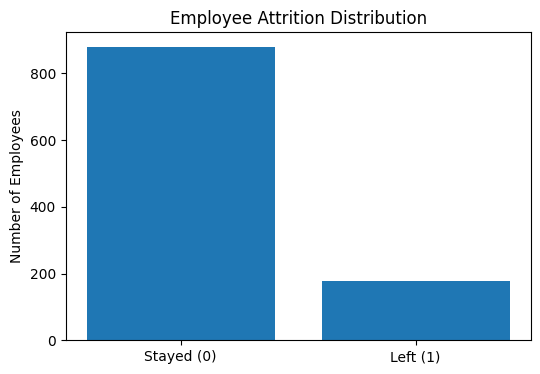

In [15]:
counts = df["Attrition"].value_counts().reindex([0, 1], fill_value=0)
plt.figure(figsize=(6,4))
plt.bar(["Stayed (0)", "Left (1)"], counts.values)
plt.title("Employee Attrition Distribution")
plt.ylabel("Number of Employees")
plt.show()

**Interpretation:** The bars show the number of employees who stayed (0) and left (1). The difference in bar height summarises the observed attrition distribution.

# Lecture 3 — Decision-Making Structures and Loops



## Nested IF statement

In [16]:
average_income = df["MonthlyIncome"].mean()
average_satisfaction = df["JobSatisfaction"].mean()

if average_income >= 5000:
    print("Average monthly income is at least 5000")
    if average_satisfaction >= 3:
        print("Average job satisfaction is at least 3")
    else:
        print("Average job satisfaction is below 3")
else:
    print("Average monthly income is below 5000")

Average monthly income is at least 5000
Average job satisfaction is below 3


**Interpretation:** A nested IF places one decision inside another. Here the conditions use dataset-level average income and satisfaction to demonstrate branching logic. The printed message depends on the actual averages calculated from this file; it is a programming exercise, not an HR policy threshold.

## IF, ELIF and ELSE

In [17]:
average_satisfaction = df["JobSatisfaction"].mean()

if average_satisfaction >= 3.5:
    print("Average job satisfaction is very high")
elif average_satisfaction >= 3:
    print("Average job satisfaction is high")
elif average_satisfaction >= 2:
    print("Average job satisfaction is moderate")
else:
    print("Average job satisfaction is low")

Average job satisfaction is moderate


**Interpretation:** The IF/ELIF/ELSE structure checks conditions in order and executes the first matching branch. The cut-offs are used to practise conditional logic on the satisfaction scale; they should not be treated as official organisational benchmarks.

## FOR loop through employee records

In [18]:
for status in df["Attrition"].head(10):
    if status == 1:
        print("Employee attrition status: Left")
    else:
        print("Employee attrition status: Stayed")

Employee attrition status: Left
Employee attrition status: Stayed
Employee attrition status: Left
Employee attrition status: Stayed
Employee attrition status: Stayed
Employee attrition status: Stayed
Employee attrition status: Stayed
Employee attrition status: Stayed
Employee attrition status: Stayed
Employee attrition status: Stayed


**Interpretation:** The loop reads the first ten attrition labels one by one and converts them into plain-language messages. It demonstrates how repetitive tasks can be automated without manually checking each record.

## FOR loop with range() and iloc

In [19]:
for i in range(10):
    print(
        "Employee Number:", df["EmployeeNumber"].iloc[i],
        "| Department:", df["Department"].iloc[i],
        "| Attrition:", df["Attrition"].iloc[i]
    )

Employee Number: 1 | Department: Sales | Attrition: 1
Employee Number: 2 | Department: Research & Development | Attrition: 0
Employee Number: 4 | Department: Research & Development | Attrition: 1
Employee Number: 5 | Department: Research & Development | Attrition: 0
Employee Number: 7 | Department: Research & Development | Attrition: 0
Employee Number: 8 | Department: Research & Development | Attrition: 0
Employee Number: 10 | Department: Research & Development | Attrition: 0
Employee Number: 11 | Department: Research & Development | Attrition: 0
Employee Number: 12 | Department: Research & Development | Attrition: 0
Employee Number: 13 | Department: Research & Development | Attrition: 0


**Interpretation:** `range()` generates row positions and `.iloc[]` retrieves values at those positions. The loop prints a small employee-level sample. Employee numbers are identifiers; they should not be interpreted as measures of performance or seniority.

## WHILE loop

In [20]:
i = 0

while i < 5:
    employee_number = df["EmployeeNumber"].iloc[i]
    years_at_company = df["YearsAtCompany"].iloc[i]

    if years_at_company >= 5:
        print("Employee", employee_number, "has 5 or more years at the company")
    else:
        print("Employee", employee_number, "has less than 5 years at the company")

    i += 1

Employee 1 has 5 or more years at the company
Employee 2 has 5 or more years at the company
Employee 4 has less than 5 years at the company
Employee 5 has 5 or more years at the company
Employee 7 has less than 5 years at the company


**Interpretation:** The WHILE loop repeats until its condition becomes false. It checks five records and prints a message based on tenure. The five-record limit keeps the demonstration short; it is not a sample designed for statistical conclusions.

# Lecture 4 — Python Data Structures



## Create data structures from the dataset

In [21]:
# Each selected column becomes a Python list
department_list = df["Department"].tolist()
job_role_list = df["JobRole"].tolist()
income_list = df["MonthlyIncome"].tolist()
attrition_list = df["Attrition"].tolist()

# One employee's selected details stored as a tuple
employee = (
    df["EmployeeNumber"].iloc[0],
    df["Department"].iloc[0],
    df["JobRole"].iloc[0]
)

# Unique departments stored in a set
unique_departments = set(df["Department"])

# One employee's details stored as a dictionary
employee_details = df.iloc[0][
    ["EmployeeNumber", "Age", "Department", "JobRole", "MonthlyIncome", "Attrition"]
].to_dict()

print("First 5 departments:", department_list[:5])
print("Employee tuple:", employee)
print("Unique departments:", unique_departments)
print("Employee dictionary:", employee_details)

First 5 departments: ['Sales', 'Research & Development', 'Research & Development', 'Research & Development', 'Research & Development']
Employee tuple: (np.int64(1), 'Sales', 'Sales Executive')
Unique departments: {'Sales', 'Human Resources', 'Research & Development'}
Employee dictionary: {'EmployeeNumber': 1, 'Age': 41, 'Department': 'Sales', 'JobRole': 'Sales Executive', 'MonthlyIncome': 5993, 'Attrition': 1}


**Interpretation:** The selected DataFrame columns are converted into Python lists. Lists preserve order and can contain repeated values, which is useful when processing employee records sequentially.

## Access and modify data structures

In [22]:
print("First department:", department_list[0])
print("Last department:", department_list[-1])
print("First five departments:", department_list[:5])
print("Every second department:", department_list[::2][:10])

print("Employee number:", employee_details["EmployeeNumber"])
print("Department:", employee_details.get("Department"))
print("Location:", employee_details.get("Location", "Not Available"))

First department: Sales
Last department: Sales
First five departments: ['Sales', 'Research & Development', 'Research & Development', 'Research & Development', 'Research & Development']
Every second department: ['Sales', 'Research & Development', 'Research & Development', 'Research & Development', 'Research & Development', 'Research & Development', 'Research & Development', 'Research & Development', 'Research & Development', 'Sales']
Employee number: 1
Department: Sales
Location: Not Available


**Interpretation:** Indexing retrieves one item, negative indexing starts from the end, and slicing retrieves a subset. These operations help access selected values from a column after it has been converted into a list.

In [23]:
# Lists are mutable
department_list_copy = department_list.copy()
department_list_copy[0] = "Updated Department Label"
print("Modified list item:", department_list_copy[0])

# Tuples are immutable. Convert to list to make a modified copy.
employee_list = list(employee)
employee_list[1] = "Updated Department Label"
updated_employee_tuple = tuple(employee_list)
print("Updated tuple copy:", updated_employee_tuple)

Modified list item: Updated Department Label
Updated tuple copy: (np.int64(1), 'Updated Department Label', 'Sales Executive')


**Interpretation:** Lists can be modified, while tuples cannot be modified after creation. The code changes a copy of the department list, not the original DataFrame. This distinction protects the source dataset from accidental changes during practice.

## Built-in functions

In [24]:
print("Number of employees:", len(income_list))
print("Total monthly income:", sum(income_list))
print("Average monthly income:", round(sum(income_list) / len(income_list), 2))
print("Highest monthly income:", max(income_list))
print("Lowest monthly income:", min(income_list))
print("Top 5 monthly incomes:", sorted(income_list, reverse=True)[:5])

Number of employees: 1058
Total monthly income: 7010250
Average monthly income: 6625.95
Highest monthly income: 19999
Lowest monthly income: 1009
Top 5 monthly incomes: [19999, 19973, 19943, 19926, 19859]


**Interpretation:** `len()` counts list items, `sum()` totals numeric values and `round()` controls displayed decimal places. The average calculated from total income divided by the number of records should agree with the corresponding mean, subject to rounding.

## Loops and dictionaries: count employees by department

In [25]:
employees_per_department = {}

for department in department_list:
    if department in employees_per_department:
        employees_per_department[department] += 1
    else:
        employees_per_department[department] = 1

print("Employees per department:", employees_per_department)

largest_department = max(employees_per_department, key=employees_per_department.get)
print("Department with the highest employee count:", largest_department)
print("Employee count:", employees_per_department[largest_department])

Employees per department: {'Sales': 319, 'Research & Development': 701, 'Human Resources': 38}
Department with the highest employee count: Research & Development
Employee count: 701


**Interpretation:** The dictionary stores each department as a key and its employee count as the value. This is a simple way to build a frequency summary using a loop and conditional logic.

## Count attrition using a dictionary

In [26]:
attrition_count = {}

for status in attrition_list:
    if status in attrition_count:
        attrition_count[status] += 1
    else:
        attrition_count[status] = 1

print("Attrition count:", attrition_count)

Attrition count: {1: 179, 0: 879}


**Interpretation:** This dictionary counts the two attrition codes (0 = stayed; 1 = left). The counts can be compared with the frequency table in Lecture 2.

## Filtering employee records

In [27]:
high_income_employees = []

for income in income_list:
    if income > 50000:
        high_income_employees.append(income)

print("Number of employees with monthly income above 50000:", len(high_income_employees))
print("First 10 matching income values:", high_income_employees[:10])

Number of employees with monthly income above 50000: 0
First 10 matching income values: []


**Interpretation:** The loop filters monthly income values above the selected threshold and stores them in a new list. The threshold is used to practise filtering, not to define a formal high-income grade. The original dataset remains unchanged.

In [28]:
departments_with_attrition = set()

for department, status in zip(department_list, attrition_list):
    if status == 1:
        departments_with_attrition.add(department)

print("Departments with employees who left:", departments_with_attrition)

Departments with employees who left: {'Sales', 'Human Resources', 'Research & Development'}


**Interpretation:** A set stores unique values only. This code identifies the distinct departments in which at least one record has attrition marked `Yes`. It does not compare attrition rates across departments; that requires counts and denominators for each department.

In [29]:
attrition_job_roles = set()

for job_role, status in zip(job_role_list, attrition_list):
    if status == 1:
        attrition_job_roles.add(job_role)

print("Job roles with employees who left:", attrition_job_roles)

Job roles with employees who left: {'Sales Executive', 'Research Director', 'Laboratory Technician', 'Sales Representative', 'Healthcare Representative', 'Manufacturing Director', 'Human Resources', 'Manager', 'Research Scientist'}


**Interpretation:** This set identifies distinct job roles with at least one attrition record. It shows which roles appear in the attrition group, but not which role has the highest attrition rate.

# Lecture 5 — Descriptive Statistics and Data Visualisation

This is where descriptive statistics belongs in the lecture sequence.

## Numerical descriptive statistics

In [30]:
numeric_columns = df.select_dtypes(include=np.number).columns
# Exclude identifiers and category/ordinal labels from continuous summaries.
exclude_from_continuous = {"EmployeeNumber", "EmployeeCount", "StandardHours", "Attrition", "Education", "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "RelationshipSatisfaction", "JobInvolvement", "PerformanceRating", "JobLevel", "StockOptionLevel"}
continuous_columns = [col for col in numeric_columns if col not in exclude_from_continuous]
numeric_summary = df[continuous_columns].describe().T
numeric_summary

,count,mean,std,min,25%,50%,75%,max
Age,1058.0,37.055766,9.410421,18.0,30.00,36.0,43.0,60.0
DailyRate,1058.0,809.542533,408.478049,102.0,465.25,817.5,1168.5,1499.0
DistanceFromHome,1058.0,8.978261,8.040608,1.0,2.00,7.0,13.0,29.0
HourlyRate,1058.0,65.643667,20.324861,30.0,48.00,65.0,83.0,100.0
MonthlyIncome,1058.0,6625.945180,4837.695042,1009.0,2900.25,4903.5,8736.5,19999.0
MonthlyRate,1058.0,14267.281664,7048.077305,2094.0,8277.25,14201.0,20364.0,26999.0
NumCompaniesWorked,1058.0,2.706994,2.523526,0.0,1.00,2.0,4.0,9.0
PercentSalaryHike,1058.0,15.155955,3.641097,11.0,12.00,14.0,18.0,25.0
TotalWorkingYears,1058.0,11.435728,8.016429,0.0,6.00,10.0,16.0,40.0
TrainingTimesLastYear,1058.0,2.769376,1.302689,0.0,2.00,3.0,3.0,6.0


**Interpretation:** The transposed summary presents one numeric variable per row. Review the mean and median for typical values, standard deviation for spread, and quartiles for the distribution. Identifier columns and numeric-coded categories may appear here too, so interpret them carefully rather than treating every numeric column as a meaningful measurement.

In [31]:
median_values = df[continuous_columns].median()
median_values

,0
Age,36.0
DailyRate,817.5
DistanceFromHome,7.0
HourlyRate,65.0
MonthlyIncome,4903.5
MonthlyRate,14201.0
NumCompaniesWorked,2.0
PercentSalaryHike,14.0
TotalWorkingYears,10.0
TrainingTimesLastYear,3.0


**Interpretation:** The median is the middle value after sorting observations. Comparing mean and median can reveal skew: a mean much higher than the median may indicate a right-skewed distribution or unusually high values.

## Categorical descriptive statistics

In [32]:
categorical_columns = df.select_dtypes(include=["object", "category"]).columns
# Binary attrition and coded rating fields are categorical in meaning.
categorical_columns = categorical_columns.union(pd.Index(["Attrition", "JobSatisfaction", "WorkLifeBalance", "EnvironmentSatisfaction"]))
categorical_columns

Index(['Attrition', 'Attrition_Label', 'BusinessTravel', 'Department',
       'EducationField', 'Education_Label', 'EnvironmentSatisfaction',
       'EnvironmentSatisfaction_Label', 'Gender', 'JobInvolvement_Label',
       'JobRole', 'JobSatisfaction', 'JobSatisfaction_Label', 'MaritalStatus',
       'Over18', 'OverTime', 'PerformanceRating_Label',
       'RelationshipSatisfaction_Label', 'WorkLifeBalance',
       'WorkLifeBalance_Label'],
      dtype='object')

**Interpretation:** This selects columns stored as text. These are generally categorical variables, such as department, job role and attrition status. Some ordinal ratings may be stored as numbers and therefore will not appear in this list.

In [33]:
for column in categorical_columns:
    print("\\n", column)
    print(df[column].value_counts())

\n Attrition
Attrition
0    879
1    179
Name: count, dtype: int64
\n Attrition_Label
Attrition_Label
No     879
Yes    179
Name: count, dtype: int64
\n BusinessTravel
BusinessTravel
Travel_Rarely        746
Travel_Frequently    205
Non-Travel           107
Name: count, dtype: int64
\n Department
Department
Research & Development    701
Sales                     319
Human Resources            38
Name: count, dtype: int64
\n EducationField
EducationField
Life Sciences       436
Medical             330
Marketing           122
Technical Degree     96
Other                59
Human Resources      15
Name: count, dtype: int64
\n Education_Label
Education_Label
Bachelor         410
Master           276
College          208
Below College    131
Doctor            33
Name: count, dtype: int64
\n EnvironmentSatisfaction
EnvironmentSatisfaction
3    335
4    314
1    209
2    200
Name: count, dtype: int64
\n EnvironmentSatisfaction_Label
EnvironmentSatisfaction_Label
High         335
Very High    

**Interpretation:** The frequency counts show how many records belong to each category for every text column. They help identify common groups and categories with very few observations.

In [34]:
for column in categorical_columns:
    print("\\n", column)
    print(df[column].value_counts(normalize=True) * 100)

\n Attrition
Attrition
0    83.081285
1    16.918715
Name: proportion, dtype: float64
\n Attrition_Label
Attrition_Label
No     83.081285
Yes    16.918715
Name: proportion, dtype: float64
\n BusinessTravel
BusinessTravel
Travel_Rarely        70.510397
Travel_Frequently    19.376181
Non-Travel           10.113422
Name: proportion, dtype: float64
\n Department
Department
Research & Development    66.257089
Sales                     30.151229
Human Resources            3.591682
Name: proportion, dtype: float64
\n EducationField
EducationField
Life Sciences       41.209830
Medical             31.190926
Marketing           11.531191
Technical Degree     9.073724
Other                5.576560
Human Resources      1.417769
Name: proportion, dtype: float64
\n Education_Label
Education_Label
Bachelor         38.752363
Master           26.086957
College          19.659735
Below College    12.381853
Doctor            3.119093
Name: proportion, dtype: float64
\n EnvironmentSatisfaction
Environment

**Interpretation:** Percentages express each category's frequency as a share of the non-missing records in that column. They are easier to compare across columns with different numbers of categories.

In [35]:
for column in categorical_columns:
    modes = df[column].mode()
    if not modes.empty:
        print(column, ":", modes.iloc[0])

Attrition : 0
Attrition_Label : No
BusinessTravel : Travel_Rarely
Department : Research & Development
EducationField : Life Sciences
Education_Label : Bachelor
EnvironmentSatisfaction : 3
EnvironmentSatisfaction_Label : High
Gender : Male
JobInvolvement_Label : High
JobRole : Sales Executive
JobSatisfaction : 4
JobSatisfaction_Label : Very High
MaritalStatus : Married
Over18 : Y
OverTime : No
PerformanceRating_Label : Excellent
RelationshipSatisfaction_Label : High
WorkLifeBalance : 3
WorkLifeBalance_Label : Better


**Interpretation:** The mode is the most frequently occurring category or value. For categorical variables, it identifies the most common response or group; ties may produce more than one mode.

In [36]:
complete_summary = df.describe(include="all").T
complete_summary

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1058.0,NaN,NaN,NaN,37.055766,9.410421,18.0,30.0,36.0,43.0,60.0
Attrition,1058.0,NaN,NaN,NaN,0.169187,0.375094,0.0,0.0,0.0,0.0,1.0
BusinessTravel,1058,3,Travel_Rarely,746,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1058.0,NaN,NaN,NaN,809.542533,408.478049,102.0,465.25,817.5,1168.5,1499.0
Department,1058,3,Research & Development,701,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1058.0,NaN,NaN,NaN,8.978261,8.040608,1.0,2.0,7.0,13.0,29.0
Education,1058.0,NaN,NaN,NaN,2.879017,1.031442,1.0,2.0,3.0,4.0,5.0
EducationField,1058,6,Life Sciences,436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1058.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1058.0,NaN,NaN,NaN,731.753308,431.418209,1.0,364.5,723.5,1101.75,1487.0


**Interpretation:** `describe(include='all')` combines summaries for numeric and categorical columns. Numeric columns show measures such as mean and quartiles; text columns show counts, unique values, the most frequent category and its frequency.

## Single-variable statistics: Monthly Income

Mean, median, mode, minimum, maximum, standard deviation and range.

In [37]:
income = df["MonthlyIncome"]

print("Mean:", round(income.mean(), 2))
print("Median:", income.median())
print("Mode:", income.mode().iloc[0])
print("Minimum:", income.min())
print("Maximum:", income.max())
print("Standard deviation:", round(income.std(), 2))
print("Range:", income.max() - income.min())

Mean: 6625.95
Median: 4903.5
Mode: 2342
Minimum: 1009
Maximum: 19999
Standard deviation: 4837.7
Range: 18990


**Interpretation:** These measures describe the distribution of monthly income. The mean uses every value and can be influenced by very high incomes; the median is less sensitive to extreme values; the range (maximum minus minimum) shows the total spread. Use the actual output values when writing the final business interpretation.

#Lecture 6 — Data Visualisation and Missing-Value Visualisation
The lecture introduces bar charts, line charts, pie charts, histograms, scatter plots and heat plots. The employee dataset contains no date or time field, so the visualisations focus on employee groups, distributions and relationships.

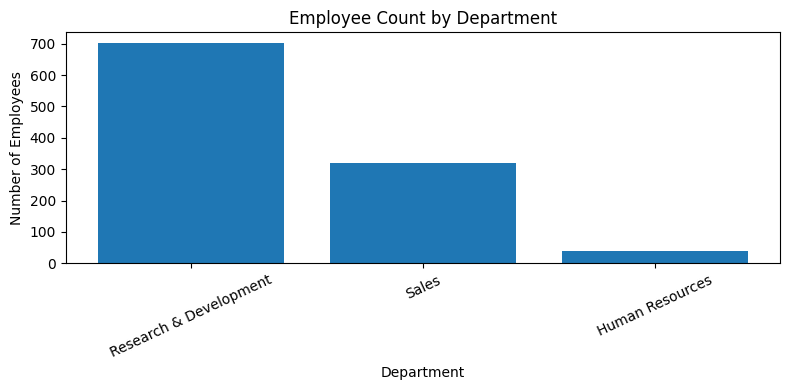

In [38]:
counts = df["Department"].value_counts()
plt.figure(figsize=(8,4))
plt.bar(counts.index, counts.values)
plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Interpretation: The chart compares the number of employees across departments. It shows how the workforce is distributed and provides context when comparing department-level HR patterns.

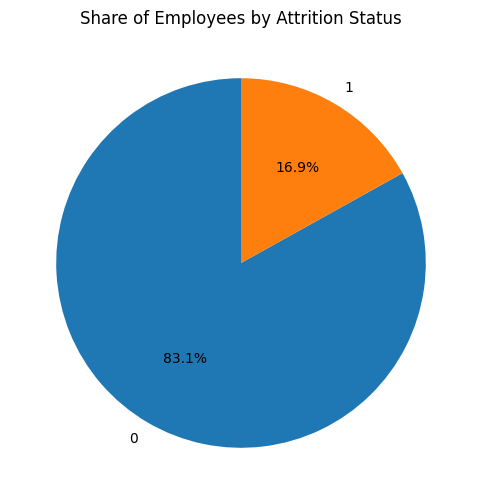

In [39]:
# Share of employees by attrition status
attrition_counts = df["Attrition"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(attrition_counts, labels=attrition_counts.index, autopct="%.1f%%", startangle=90)
plt.title("Share of Employees by Attrition Status")
plt.show()

Interpretation: The pie chart shows the proportion of employees who stayed and those who left in this dataset. The attrition share provides an overall retention baseline for the analysis.

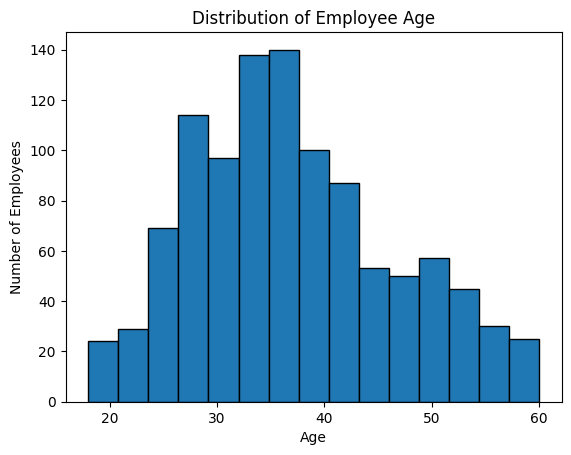

In [40]:
# Distribution of employee age
plt.hist(df["Age"].dropna(), bins=15, edgecolor="black")
plt.title("Distribution of Employee Age")
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.show()

Interpretation: The histogram shows which age ranges are most represented in the employee dataset and whether the age distribution is concentrated or spread across a wider range.

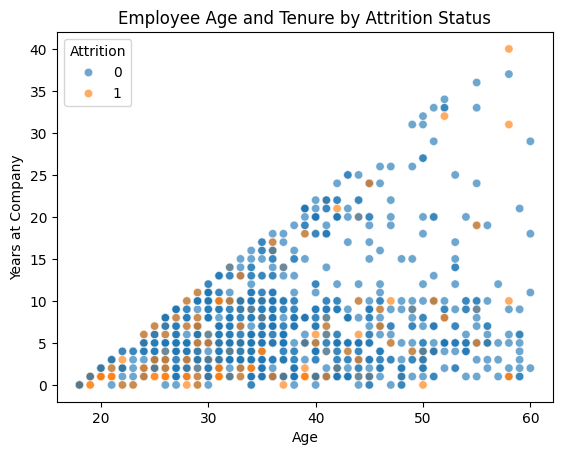

In [41]:
# Age and company tenure by attrition status
sns.scatterplot(data=df, x="Age", y="YearsAtCompany", hue="Attrition", alpha=0.65)
plt.title("Employee Age and Tenure by Attrition Status")
plt.xlabel("Age")
plt.ylabel("Years at Company")
plt.show()

Interpretation: Each point represents an employee. The chart compares age and tenure patterns for employees who stayed and employees who left. It can reveal clusters or differences, but it does not establish why an employee left.

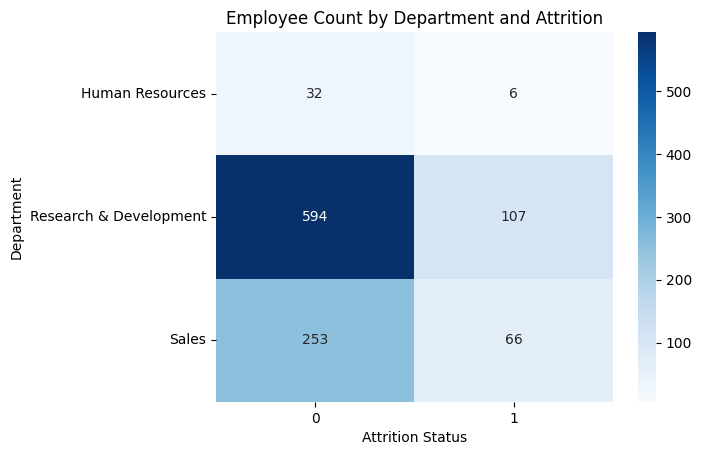

In [42]:
# Employee count by department and attrition status
heat_data = pd.crosstab(df["Department"], df["Attrition"])
sns.heatmap(heat_data, annot=True, fmt="d", cmap="Blues")
plt.title("Employee Count by Department and Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Department")
plt.show()

Interpretation: The heatmap compares the number of employees who stayed and left in each department. The counts should be read alongside department size because larger departments may naturally have more employees in both groups.

# Lecture 7 — Missing Values, Unusual Values and Data Manipulation
The checks use the supplied `Cleaned_Data` worksheet to examine completeness, duplicates and potential inconsistencies.

In [43]:
# Missing-value review on the supplied cleaned dataset
working_df = df.copy()
missing_count = working_df.isna().sum()
missing_percent = (working_df.isna().mean() * 100).round(2)
missing_table = pd.DataFrame({"Missing Count": missing_count, "Missing Percent": missing_percent})
display(missing_table)
print("Duplicate employee IDs:", working_df["EmployeeNumber"].duplicated().sum())
print("Duplicate rows:", working_df.duplicated().sum())

,Missing Count,Missing Percent
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0


Duplicate employee IDs: 0
Duplicate rows: 0


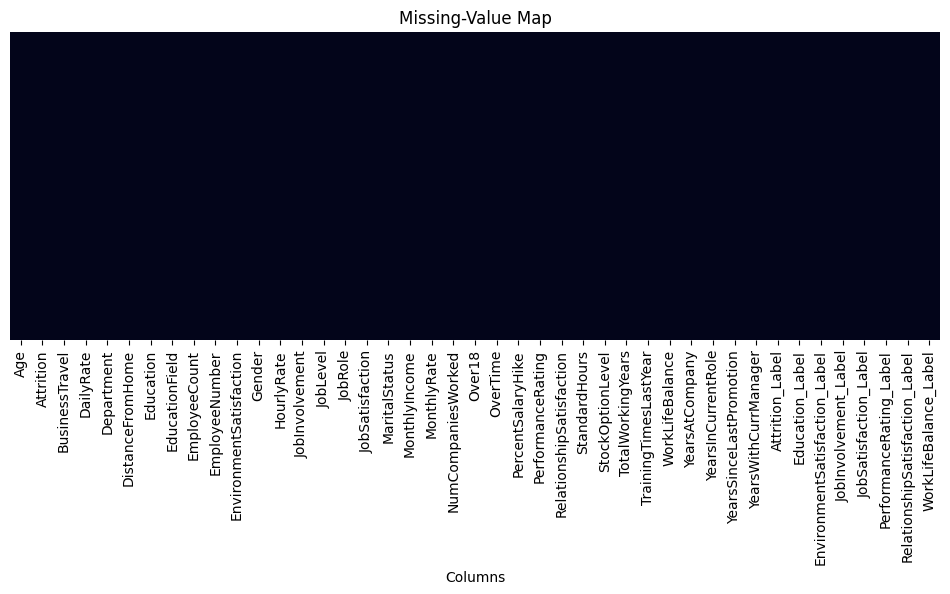

In [44]:
# Visual representation of missing values
plt.figure(figsize=(12, 4))
sns.heatmap(working_df.isna(), cbar=False, yticklabels=False)
plt.title("Missing-Value Map")
plt.xlabel("Columns")
plt.show()

Interpretation: Blank positions in the heatmap represent missing values. A fully filled map indicates that no missing cells were detected in the displayed dataset.

In [45]:
# Validation checks for unusual or inconsistent values
checks = {
    "Age outside 18–65": ~df["Age"].between(18, 65),
    "MonthlyIncome <= 0": df["MonthlyIncome"] <= 0,
    "DistanceFromHome < 1": df["DistanceFromHome"] < 1,
    "YearsAtCompany > TotalWorkingYears": df["YearsAtCompany"] > df["TotalWorkingYears"],
    "JobSatisfaction outside 1–4": ~df["JobSatisfaction"].between(1, 4),
    "WorkLifeBalance outside 1–4": ~df["WorkLifeBalance"].between(1, 4)
}
for label, condition in checks.items():
    print(label, ":", int(condition.sum()))

Age outside 18–65 : 0
MonthlyIncome <= 0 : 0
DistanceFromHome < 1 : 0
YearsAtCompany > TotalWorkingYears : 0
JobSatisfaction outside 1–4 : 0
WorkLifeBalance outside 1–4 : 0


Interpretation: These counts show how many records meet each unusual-value condition. A non-zero count highlights records that may need context or verification; a flag alone does not prove that a value is incorrect.


# Lecture 8 — Data Cleaning and Outlier Treatment
IQR flags and boxplots are calculated on `Cleaned_Data`. The cleaned records are retained for the subsequent analysis.

In [46]:
# Potential outliers using the IQR rule
outlier_variables = [
    "Age", "DistanceFromHome", "MonthlyIncome", "TotalWorkingYears",
    "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]
outlier_rows = []
for col in outlier_variables:
    q1 = working_df[col].quantile(0.25)
    q3 = working_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((working_df[col] < lower) | (working_df[col] > upper)).sum())
    outlier_rows.append([col, q1, q3, lower, upper, count])

outlier_summary = pd.DataFrame(
    outlier_rows,
    columns=["Variable", "Q1", "Q3", "Lower Limit", "Upper Limit", "Potential Outliers"]
)
display(outlier_summary.round(2))

,Variable,Q1,Q3,Lower Limit,Upper Limit,Potential Outliers
0,Age,30.00,43.0,10.50,62.50,0
1,DistanceFromHome,2.00,13.0,-14.50,29.50,0
2,MonthlyIncome,2900.25,8736.5,-5854.12,17490.88,64
3,TotalWorkingYears,6.00,16.0,-9.00,31.00,29
4,YearsAtCompany,3.00,9.0,-6.00,18.00,79
5,YearsInCurrentRole,2.00,7.0,-5.50,14.50,15
6,YearsSinceLastPromotion,0.00,3.0,-4.50,7.50,80
7,YearsWithCurrManager,2.00,7.0,-5.50,14.50,12


Interpretation: The IQR method identifies observations beyond the lower and upper statistical limits for each measure. In HR data, a high income or long tenure may be genuine, so an outlier is not automatically an error.

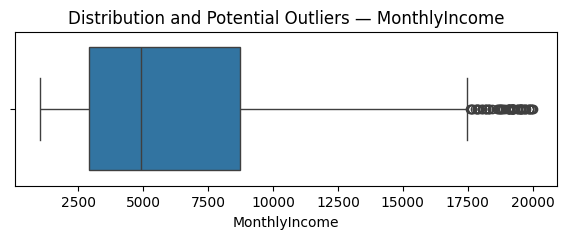

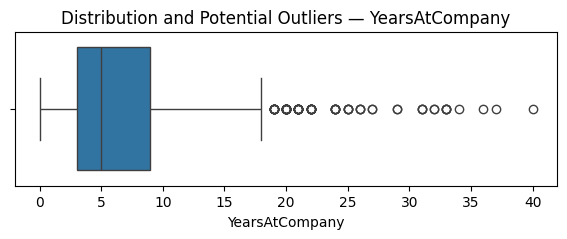

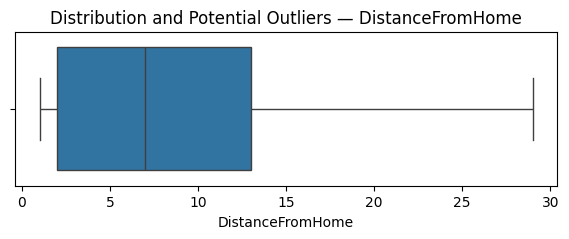

In [47]:
# Boxplots for selected continuous measures
for col in ["MonthlyIncome", "YearsAtCompany", "DistanceFromHome"]:
    plt.figure(figsize=(7, 2))
    sns.boxplot(x=working_df[col])
    plt.title("Distribution and Potential Outliers — " + col)
    plt.show()

Interpretation: The boxplots display the median, middle half of the observations and points beyond the whiskers. They help compare spread and identify unusually high or low values for further examination.

In [48]:
# Verify the cleaned dataset; do not overwrite or re-impute existing values.
working_copy = working_df.copy()
print("Missing cells:", int(working_copy.isna().sum().sum()))
print("Rows:", len(working_copy))
print("Duplicate employee IDs:", int(working_copy["EmployeeNumber"].duplicated().sum()))
print("Data is retained unchanged for subsequent analysis.")

Missing cells: 0
Rows: 1058
Duplicate employee IDs: 0
Data is retained unchanged for subsequent analysis.


**Interpretation:** The cleaned dataset is checked for missing cells and duplicate identifiers. No additional imputation is applied to the supplied cleaned records.

#Lectures 9–10 — Advanced Data Visualisation
These visualisations compare attrition across departments and job roles, examine income and overtime patterns, and explore the relationship between total work experience and tenure at the current company.

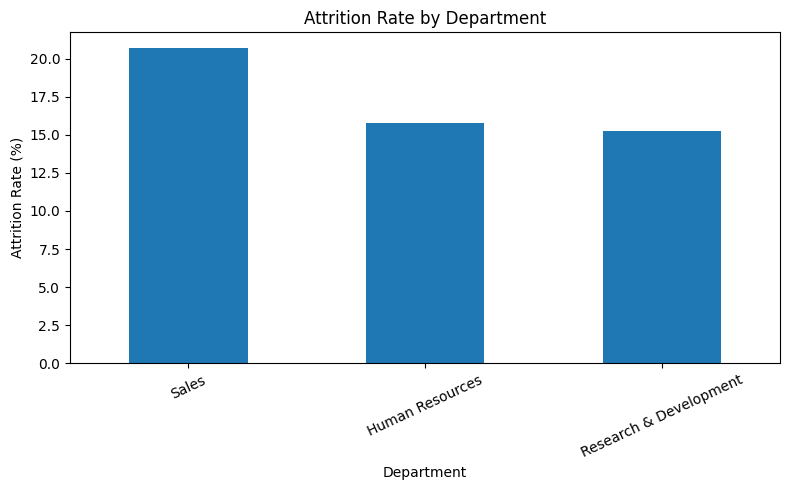

,Attrition Rate (%)
Department,
Sales,20.69
Human Resources,15.79
Research & Development,15.26


In [49]:
rate_department = df.groupby("Department")["Attrition"].mean().mul(100).sort_values(ascending=False)
rate_department.plot(kind="bar", figsize=(8, 5))
plt.title("Attrition Rate by Department")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Department")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
display(rate_department.round(2).rename("Attrition Rate (%)").to_frame())

Interpretation: Department-level attrition rates allow comparison across departments while accounting for differences in department size. Higher percentages indicate a larger share of employees leaving within that department.

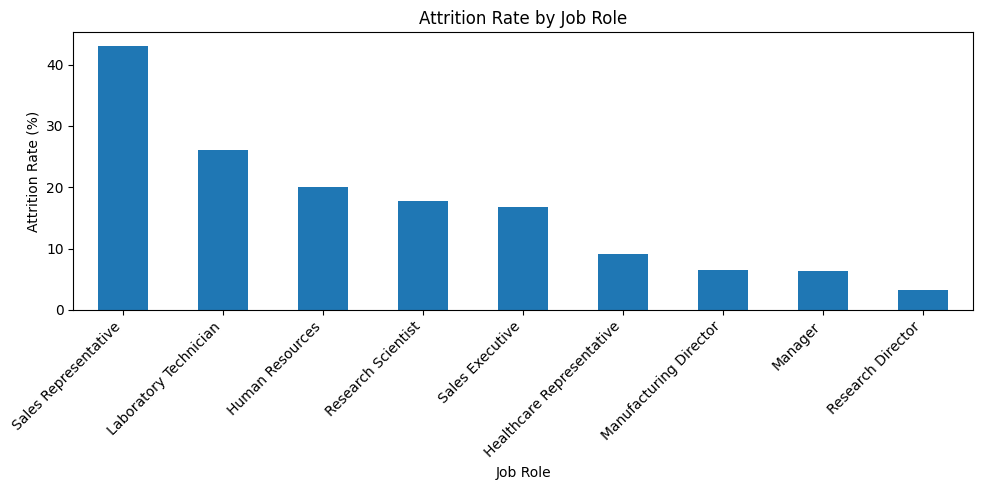

,Attrition Rate (%)
JobRole,
Sales Representative,43.10
Laboratory Technician,26.06
Human Resources,20.00
Research Scientist,17.76
Sales Executive,16.81
Healthcare Representative,9.09
Manufacturing Director,6.54
Manager,6.33
Research Director,3.23


In [50]:
rate_role = df.groupby("JobRole")["Attrition"].mean().mul(100).sort_values(ascending=False)
rate_role.plot(kind="bar", figsize=(10, 5))
plt.title("Attrition Rate by Job Role")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Job Role")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(rate_role.round(2).rename("Attrition Rate (%)").to_frame())

Interpretation: The chart ranks job roles by the proportion of employees who left. Differences between roles can help HR identify where retention patterns vary across the organisation.

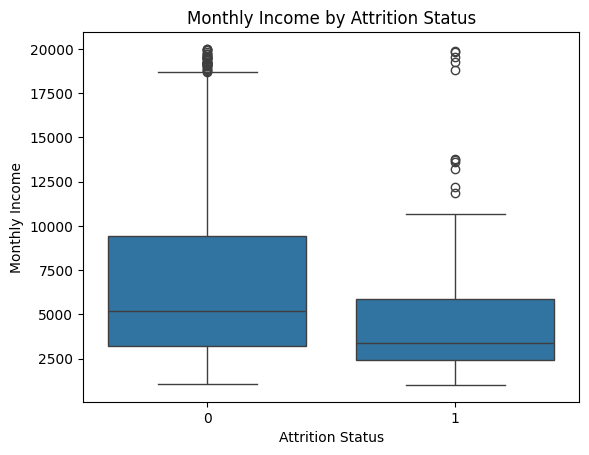

In [51]:
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Monthly Income by Attrition Status")
plt.xlabel("Attrition Status")
plt.ylabel("Monthly Income")
plt.show()

**Interpretation:** The boxplot compares the monthly-income distributions of employees who stayed (0) and left (1), including their medians, spread and potential outliers.

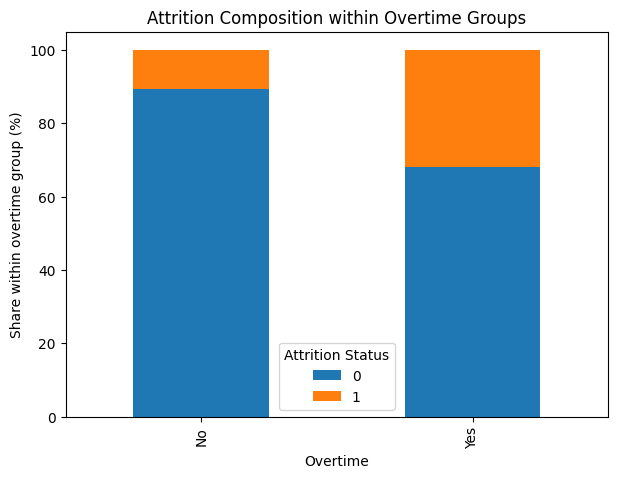

Attrition,0,1
OverTime,,
No,89.21,10.79
Yes,68.08,31.92


In [52]:
overtime_table = pd.crosstab(df["OverTime"], df["Attrition"], normalize="index") * 100
overtime_table.plot(kind="bar", stacked=True, figsize=(7, 5))
plt.title("Attrition Composition within Overtime Groups")
plt.ylabel("Share within overtime group (%)")
plt.xlabel("Overtime")
plt.legend(title="Attrition Status")
plt.show()
display(overtime_table.round(2))

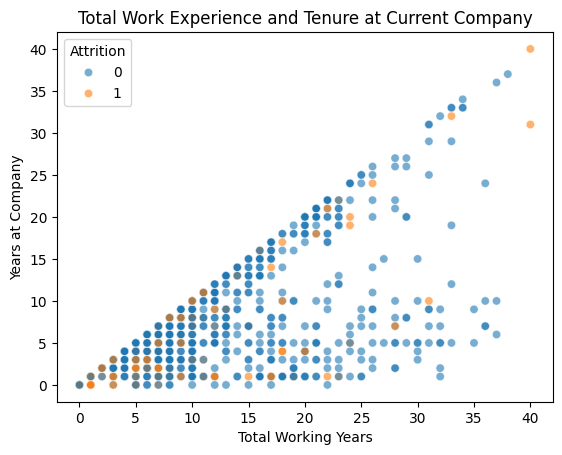

In [53]:
sns.scatterplot(data=df, x="TotalWorkingYears", y="YearsAtCompany", hue="Attrition", alpha=0.6)
plt.title("Total Work Experience and Tenure at Current Company")
plt.xlabel("Total Working Years")
plt.ylabel("Years at Company")
plt.show()

The scatter plot compares employees' overall work experience with their tenure at the current company. The relationship is expected to be positive because current-company tenure is part of total work experience; the colour groups show how attrition status is distributed across the plot.

#Lecture 11 — Count, Box, Violin, Strip and Swarm Plots
The plots examine employee counts by job role and compare tenure, income, job satisfaction and work-life balance across attrition groups.

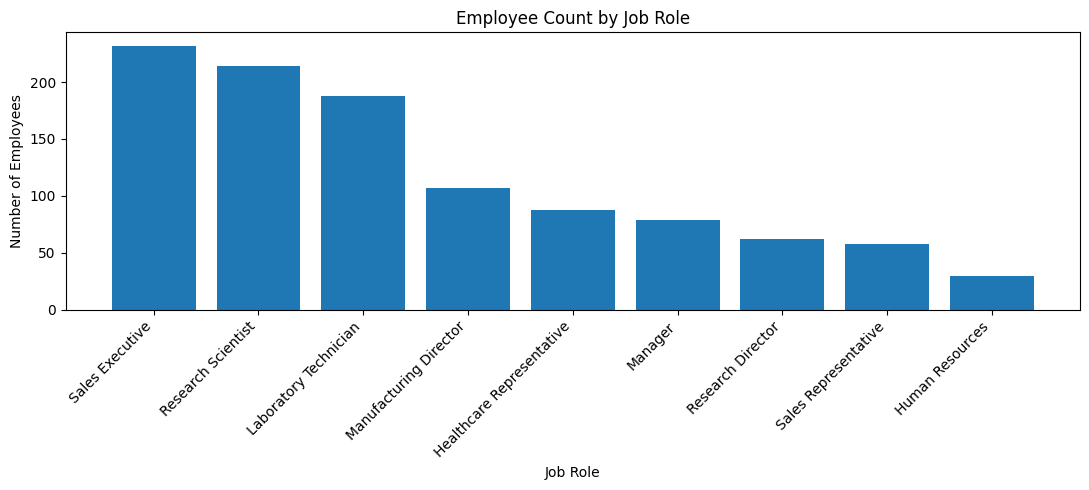

In [54]:
counts = df["JobRole"].value_counts()
plt.figure(figsize=(11,5))
plt.bar(counts.index, counts.values)
plt.title("Employee Count by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Interpretation: The count plot shows the number of employees in each job role. It highlights the relative size of role groups, which provides context for role-level attrition comparisons.

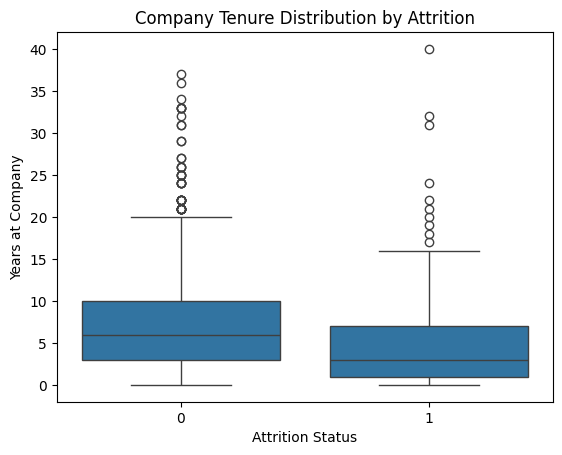

In [55]:
sns.boxplot(data=df, x="Attrition", y="YearsAtCompany")
plt.title("Company Tenure Distribution by Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Years at Company")
plt.show()

Interpretation: The chart compares tenure distributions for employees who stayed and those who left. Differences in median tenure and spread indicate whether employees leaving the organisation tend to have a different tenure profile.

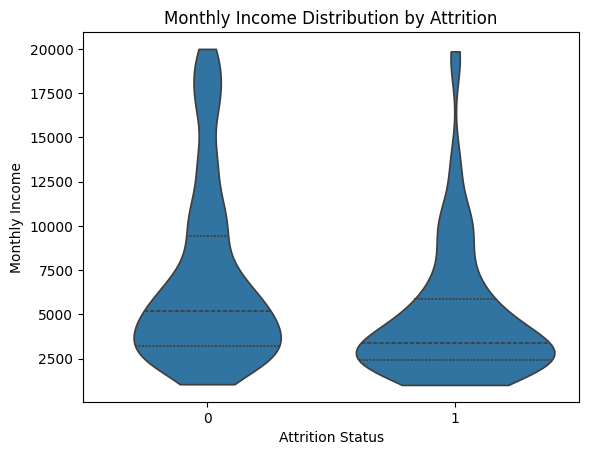

In [56]:
sns.violinplot(data=df, x="Attrition", y="MonthlyIncome", inner="quartile", cut=0)
plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Monthly Income")
plt.show()

Interpretation: The violin plot displays both the spread and density of monthly income in each attrition group. Wider sections represent income ranges where more observations are concentrated.

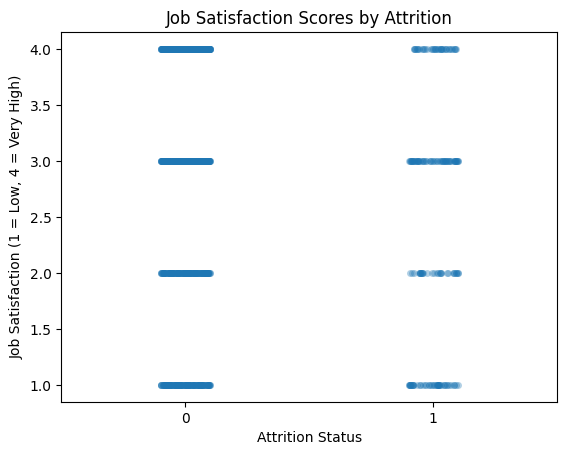

In [57]:
sns.stripplot(data=df, x="Attrition", y="JobSatisfaction", jitter=True, alpha=0.35)
plt.title("Job Satisfaction Scores by Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Job Satisfaction (1 = Low, 4 = Very High)")
plt.show()

Each point represents an employee's job satisfaction score. The distribution of points across the two attrition groups shows how satisfaction ratings are represented among employees who stayed and left.

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 21.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 41.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


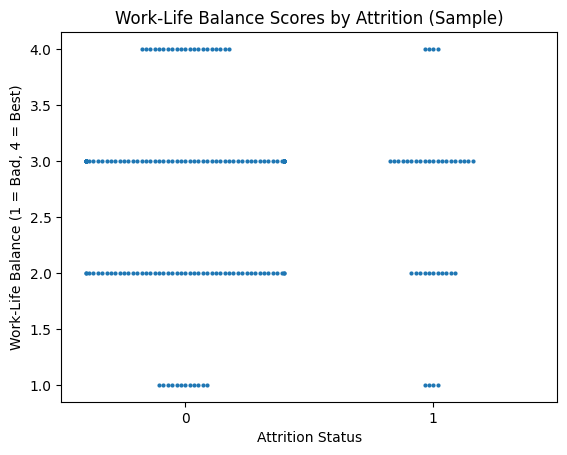

In [58]:
plot_sample = df.sample(n=min(250, len(df)), random_state=42)
sns.swarmplot(data=plot_sample, x="Attrition", y="WorkLifeBalance", size=3)
plt.title("Work-Life Balance Scores by Attrition (Sample)")
plt.xlabel("Attrition Status")
plt.ylabel("Work-Life Balance (1 = Bad, 4 = Best)")
plt.show()

Interpretation: The swarm plot displays individual work-life balance ratings for a sample of employees. It makes the concentration of ratings visible within each attrition group; the sample is used to keep overlapping points manageable.

# Lecture 12 — GeoPandas and India Map
The IBM HR dataset does not contain employee states, cities or geographic coordinates. No India map is generated from invented locations.

#Lecture 13 — Correlation, Correlation Matrix, Heatmap and Simple Linear Regression
Correlation measures the direction and strength of a linear relationship between two numeric variables. The correlation matrix summarises pairwise relationships, while simple linear regression estimates the association between one predictor and a numeric outcome.

,Age,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,MonthlyIncome
Age,1.00,0.69,0.31,0.21,0.21,0.50
TotalWorkingYears,0.69,1.00,0.63,0.46,0.41,0.78
YearsAtCompany,0.31,0.63,1.00,0.76,0.62,0.53
YearsInCurrentRole,0.21,0.46,0.76,1.00,0.55,0.39
YearsSinceLastPromotion,0.21,0.41,0.62,0.55,1.00,0.35
MonthlyIncome,0.50,0.78,0.53,0.39,0.35,1.00


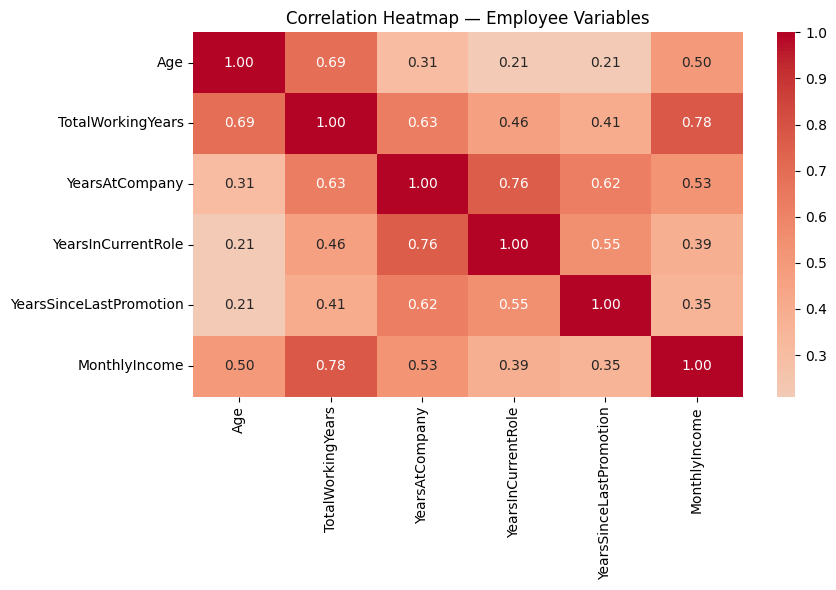

In [59]:
correlation_variables = [
    "Age", "TotalWorkingYears", "YearsAtCompany",
    "YearsInCurrentRole", "YearsSinceLastPromotion", "MonthlyIncome"
]
corr = df[correlation_variables].corr()
display(corr.round(2))
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap — Employee Variables")
plt.tight_layout()
plt.show()

Interpretation: Correlation values range from -1 to +1. Positive values indicate that two variables tend to increase together, while negative values indicate that one tends to decrease as the other increases. Values closer to zero indicate a weaker linear relationship. Correlation does not establish causation.

In [60]:
import statsmodels.formula.api as smf

simple_model = smf.ols("YearsAtCompany ~ TotalWorkingYears", data=df).fit()
print(simple_model.summary())

                            OLS Regression Results                            
Dep. Variable:         YearsAtCompany   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     685.4
Date:                Fri, 27 Nov 2026   Prob (F-statistic):          7.88e-117
Time:                        14:56:24   Log-Likelihood:                -3177.6
No. Observations:                1058   AIC:                             6359.
Df Residuals:                    1056   BIC:                             6369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             1.4582      0.26

Interpretation: This regression estimates the association between total work experience and years at the current company. The slope represents the estimated change in company tenure associated with one additional year of total work experience. R-squared indicates the proportion of variation in tenure explained by this one-predictor model. The relationship is not causal.

#Lecture 14 — Multiple Linear Regression, Moderation / Interaction Effect and PCA
The numeric outcome is YearsAtCompany. The first regression includes several employee and workplace variables. The second adds an interaction between overtime and centred job satisfaction to examine whether the association between job satisfaction and tenure differs by overtime status.

In [61]:
model_data = df[
    ["YearsAtCompany", "Age", "TotalWorkingYears", "JobLevel",
     "DistanceFromHome", "JobSatisfaction", "EnvironmentSatisfaction",
     "WorkLifeBalance", "OverTime", "Department"]
].dropna().copy()

model_data["JobSatisfaction_c"] = (
    model_data["JobSatisfaction"] - model_data["JobSatisfaction"].mean()
)

model_1 = smf.ols(
    "YearsAtCompany ~ Age + TotalWorkingYears + JobLevel + DistanceFromHome "
    "+ JobSatisfaction_c + EnvironmentSatisfaction + WorkLifeBalance "
    "+ C(OverTime) + C(Department)",
    data=model_data
).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:         YearsAtCompany   R-squared:                       0.428
Model:                            OLS   Adj. R-squared:                  0.423
Method:                 Least Squares   F-statistic:                     78.37
Date:                Fri, 27 Nov 2026   Prob (F-statistic):          1.00e-119
Time:                        14:56:24   Log-Likelihood:                -3146.6
No. Observations:                1058   AIC:                             6315.
Df Residuals:                    1047   BIC:                             6370.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

Interpretation: The multiple regression estimates the association between several predictors and company tenure while holding the other included variables constant. Categorical predictors are represented through indicator variables, with a reference category used for comparison. Coefficients and p-values show the direction, size and statistical evidence for each association.

In [62]:
model_2 = smf.ols(
    "YearsAtCompany ~ Age + TotalWorkingYears + JobLevel + DistanceFromHome "
    "+ EnvironmentSatisfaction + WorkLifeBalance + C(Department) "
    "+ C(OverTime) * JobSatisfaction_c",
    data=model_data
).fit()

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:         YearsAtCompany   R-squared:                       0.428
Model:                            OLS   Adj. R-squared:                  0.422
Method:                 Least Squares   F-statistic:                     71.18
Date:                Fri, 27 Nov 2026   Prob (F-statistic):          9.02e-119
Time:                        14:56:24   Log-Likelihood:                -3146.6
No. Observations:                1058   AIC:                             6317.
Df Residuals:                    1046   BIC:                             6377.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

Interpretation: The interaction term tests whether the relationship between centred job satisfaction and company tenure differs between overtime groups. A statistically meaningful interaction would indicate that the estimated job-satisfaction association is not the same for employees with and without overtime.

In [63]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

y_actual = model_data["YearsAtCompany"]
comparison = pd.DataFrame({
    "Measure": [
        "R-squared", "Adjusted R-squared", "AIC", "BIC",
        "F-statistic", "F-test p-value", "RMSE (in-sample)", "MAE (in-sample)"
    ],
    "Model 1": [
        model_1.rsquared, model_1.rsquared_adj, model_1.aic, model_1.bic,
        model_1.fvalue, model_1.f_pvalue,
        mean_squared_error(y_actual, model_1.fittedvalues) ** 0.5,
        mean_absolute_error(y_actual, model_1.fittedvalues)
    ],
    "Model 2": [
        model_2.rsquared, model_2.rsquared_adj, model_2.aic, model_2.bic,
        model_2.fvalue, model_2.f_pvalue,
        mean_squared_error(y_actual, model_2.fittedvalues) ** 0.5,
        mean_absolute_error(y_actual, model_2.fittedvalues)
    ]
})
display(comparison.round(4))

,Measure,Model 1,Model 2
0,R-squared,0.4281,0.4281
1,Adjusted R-squared,0.4226,0.4221
2,AIC,6315.2066,6317.1890
3,BIC,6369.8121,6376.7587
4,F-statistic,78.3666,71.1771
5,F-test p-value,0.0000,0.0000
6,RMSE (in-sample),4.7359,4.7358
7,MAE (in-sample),3.4144,3.4140


Interpretation: R-squared and adjusted R-squared describe model fit, while AIC and BIC balance fit against model complexity; lower AIC or BIC is generally preferred when comparing models fitted to the same observations. RMSE and MAE express average prediction error in years of company tenure. These errors are calculated on the same data used to fit the models, so they are in-sample measures.

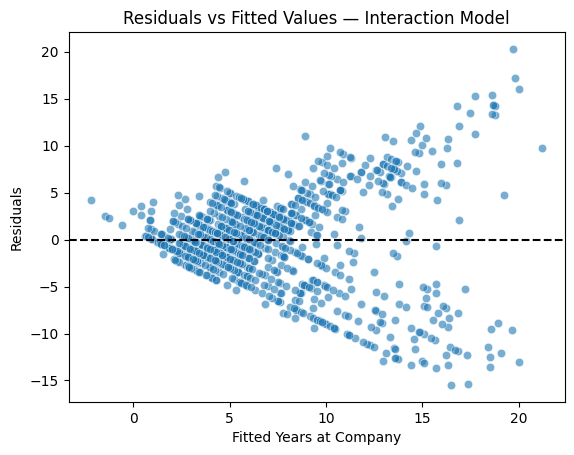

In [64]:
sns.scatterplot(x=model_2.fittedvalues, y=model_2.resid, alpha=0.6)
plt.axhline(0, linestyle="--", color="black")
plt.title("Residuals vs Fitted Values — Interaction Model")
plt.xlabel("Fitted Years at Company")
plt.ylabel("Residuals")
plt.show()

Interpretation: Residuals are the differences between observed and model-estimated tenure. A random-looking spread around zero is consistent with a reasonable linear fit, while visible curves, funnels or clusters may indicate patterns the model has not captured.

In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_variables = [
    "JobSatisfaction", "EnvironmentSatisfaction",
    "RelationshipSatisfaction", "WorkLifeBalance", "JobInvolvement"
]
pca_data = df[pca_variables].dropna()
scaler = StandardScaler()
scaled_values = scaler.fit_transform(pca_data)
pca = PCA()
pca_values = pca.fit_transform(scaled_values)

explained_variance = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
    "Explained Variance Ratio": pca.explained_variance_ratio_,
    "Cumulative Explained Variance": np.cumsum(pca.explained_variance_ratio_)
})
display(explained_variance.round(4))

,Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.2142,0.2142
1,PC2,0.2099,0.4240
2,PC3,0.2007,0.6247
3,PC4,0.1954,0.8202
4,PC5,0.1798,1.0000


Interpretation: PCA transforms the five related employee-experience measures into components that capture patterns of shared variation. The explained variance ratio shows how much of the total variation is represented by each component; cumulative variance shows how much is represented by the components together.

In [66]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_variables,
    columns=[f"PC{i+1}" for i in range(len(pca_variables))]
)
display(loadings.round(3))

,PC1,PC2,PC3,PC4,PC5
JobSatisfaction,0.650,0.189,0.209,0.484,0.513
EnvironmentSatisfaction,-0.117,-0.018,0.971,-0.038,-0.205
RelationshipSatisfaction,-0.373,0.507,-0.080,0.695,-0.338
WorkLifeBalance,-0.570,-0.490,0.055,0.334,0.566
JobInvolvement,-0.316,0.683,0.066,-0.412,0.510


Interpretation: The loading table shows how strongly each original measure contributes to each principal component. The signs and sizes of the loadings help describe the pattern represented by a component.